<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/exfinal01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto final: Predicción de precipitación extrema mediante una red neuronal implementada con NumPy

**Enfoque:** aprendizaje supervisado, clasificación binaria y serie temporal meteorológica.  
**Fuente:** archivo `datos.xlsx`, hoja `datos`, estación Sucre SENAMHI.  
**Horizonte:** predecir si el día siguiente tendrá precipitación igual o superior al percentil 95 calculado en el período de entrenamiento.

> **Alcance científico:** la base contiene variables meteorológicas, pero no contiene caudales, niveles de río ni registros observados de inundaciones. Por ello, el modelo estima eventos de precipitación extrema; no predice inundaciones confirmadas ni riesgo hidrológico integral.

## Objetivo general
Desarrollar y evaluar una red neuronal multicapa (MLP) desde cero, utilizando operaciones matriciales de NumPy y derivadas explícitas para implementar propagación hacia adelante, función de pérdida, backpropagation y optimización Adam.

## Organización
Cada sección incluye una celda Markdown de explicación y una o más celdas de código. Ejecutar en orden, de arriba hacia abajo.

## BLOQUE 1. Instalación e importación de librerías

**Objetivo.** Preparar el entorno. NumPy será responsable de las operaciones numéricas y de toda la red neuronal. Pandas leerá y organizará el Excel; Matplotlib generará gráficos; Scikit-learn se utilizará únicamente para métricas de evaluación, no para construir ni entrenar la red.

**Justificación.** La implementación manual permite observar explícitamente los cálculos que un framework como PyTorch automatiza mediante autograd.

In [ ]:
# En Google Colab, openpyxl permite leer archivos Excel.
!pip -q install openpyxl

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve
)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Librerías cargadas.")

NumPy: 2.4.6
Pandas: 2.2.3
Librerías cargadas.


## BLOQUE 2. Carga de la base de datos

**Objetivo.** Leer `datos.xlsx`, hoja `datos`.

En Google Colab se abrirá el selector de archivos. Si se ejecuta fuera de Colab y existe `/mnt/data/datos.xlsx`, se utilizará esa ruta automáticamente. En cualquier otro entorno se solicitará la ruta del archivo.

**Verificación.** Debemos comprobar el tamaño, los encabezados y una muestra de observaciones antes de continuar.

In [ ]:
try:
    from google.colab import files
    print("Entorno Google Colab detectado. Sube datos.xlsx.")
    uploaded = files.upload()
    archivo = next(iter(uploaded))
except ImportError:
    archivo = "/mnt/data/datos.xlsx" if os.path.exists("/mnt/data/datos.xlsx") else input("Ruta de datos.xlsx: ")

df = pd.read_excel(archivo, sheet_name="datos")
df.columns = df.columns.str.replace('"', '', regex=False).str.strip()

print("Dimensiones:", df.shape)
display(df.head())
print("\nColumnas:")
print(df.columns.tolist())

Entorno Google Colab detectado. Sube datos.xlsx.


Saving datos.xlsx to datos.xlsx
Dimensiones: (1826, 15)


,gestion,mes,dia,estacion,longitud,latitud,altura,Precipitación,Temperatura Máxima,Temperatura Mínima,Humedad Relativa Media,ETo,Velocidad de Viento Media,Tormenta electrica diaria,Granizo
0,2021,10,1,Sucre SENAMHI,-65.263824,-19.039881,2890.0,0.0,25.0,14.0,65.0,4.43,NaN,NaN,NaN
1,2021,10,2,Sucre SENAMHI,-65.263824,-19.039881,2890.0,34.6,26.5,11.6,71.0,5.11,NaN,NaN,NaN
2,2021,10,3,Sucre SENAMHI,-65.263824,-19.039881,2890.0,0.0,24.5,12.0,NaN,4.60,NaN,NaN,NaN
3,2021,10,4,Sucre SENAMHI,-65.263824,-19.039881,2890.0,0.0,23.0,13.0,76.0,4.10,NaN,NaN,NaN
4,2021,10,5,Sucre SENAMHI,-65.263824,-19.039881,2890.0,0.0,24.5,12.0,71.0,4.63,NaN,NaN,NaN



Columnas:
['gestion', 'mes', 'dia', 'estacion', 'longitud', 'latitud', 'altura', 'Precipitación', 'Temperatura Máxima', 'Temperatura Mínima', 'Humedad Relativa Media', 'ETo', 'Velocidad de Viento Media', 'Tormenta electrica diaria', 'Granizo']


## BLOQUE 3. Exploración y diagnóstico de calidad

**Objetivo.** Identificar tipos de datos, estadísticas descriptivas, valores faltantes, fechas repetidas y continuidad temporal.

**Justificación.** No es apropiado imputar todas las columnas indiscriminadamente. Por ejemplo, en este archivo ETo presenta una proporción elevada de faltantes y las variables de tormenta eléctrica y granizo están casi completamente vacías. Se excluirán del modelo por insuficiencia de observaciones, no porque carezcan de importancia meteorológica.

In [ ]:
print("INFORMACIÓN GENERAL")
df.info()

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe().T)

faltantes = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": 100 * df.isna().mean()
}).sort_values("porcentaje", ascending=False)
print("\nVALORES FALTANTES")
display(faltantes)

print("Estaciones:")
print(df["estacion"].value_counts(dropna=False))

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   gestion                    1826 non-null   int64  
 1   mes                        1826 non-null   int64  
 2   dia                        1826 non-null   int64  
 3   estacion                   1826 non-null   object 
 4   longitud                   1826 non-null   float64
 5   latitud                    1826 non-null   float64
 6   altura                     1826 non-null   float64
 7   Precipitación              1826 non-null   float64
 8   Temperatura Máxima         1639 non-null   float64
 9   Temperatura Mínima         1786 non-null   float64
 10  Humedad Relativa Media     1248 non-null   float64
 11  ETo                        543 non-null    float64
 12  Velocidad de Viento Media  1470 non-null   float64
 13  Tormenta electrica diaria  1

,count,mean,std,min,25%,50%,75%,max
gestion,1826.0,2023.748083,1.479378e+00,2021.000000,2022.250000,2024.000000,2025.000000,2026.000000
mes,1826.0,6.523549,3.449478e+00,1.000000,4.000000,7.000000,10.000000,12.000000
dia,1826.0,15.727820,8.801735e+00,1.000000,8.000000,16.000000,23.000000,31.000000
longitud,1826.0,-65.263824,2.032709e-12,-65.263824,-65.263824,-65.263824,-65.263824,-65.263824
latitud,1826.0,-19.039881,2.238823e-13,-19.039881,-19.039881,-19.039881,-19.039881,-19.039881
altura,1826.0,2890.000000,0.000000e+00,2890.000000,2890.000000,2890.000000,2890.000000,2890.000000
Precipitación,1826.0,1.615553,5.331869e+00,0.000000,0.000000,0.000000,0.000000,54.700000
Temperatura Máxima,1639.0,23.533130,3.203126e+00,7.500000,21.500000,23.800000,25.500000,32.800000
Temperatura Mínima,1786.0,10.256047,3.226558e+00,-1.000000,8.000000,11.000000,12.600000,17.200000
Humedad Relativa Media,1248.0,60.229968,1.783887e+01,0.000000,48.000000,61.000000,73.000000,96.000000



VALORES FALTANTES


,faltantes,porcentaje
Granizo,1825,99.945235
Tormenta electrica diaria,1811,99.178532
ETo,1283,70.262870
Humedad Relativa Media,578,31.653888
Velocidad de Viento Media,356,19.496166
Temperatura Máxima,187,10.240964
Temperatura Mínima,40,2.190581
altura,0,0.000000
latitud,0,0.000000
longitud,0,0.000000


Estaciones:
estacion
Sucre SENAMHI    1826
Name: count, dtype: int64


## BLOQUE 4. Construcción y verificación de la fecha

**Objetivo.** Unificar `gestion`, `mes` y `dia` en una variable fecha y ordenar cronológicamente.

**Importancia temporal.** La separación posterior será cronológica. No mezclaremos aleatoriamente observaciones futuras con observaciones pasadas, ya que eso produciría una evaluación optimista e incoherente con el objetivo de pronóstico.

In [ ]:
df["fecha"] = pd.to_datetime(
    dict(year=df["gestion"], month=df["mes"], day=df["dia"]),
    errors="coerce"
)
df = df.dropna(subset=["fecha"]).sort_values("fecha").reset_index(drop=True)

rango = pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="D")
fechas_faltantes = rango.difference(pd.DatetimeIndex(df["fecha"]))

print("Primera fecha:", df["fecha"].min())
print("Última fecha:", df["fecha"].max())
print("Fechas duplicadas:", df["fecha"].duplicated().sum())
print("Días sin registro:", len(fechas_faltantes))
print("Registros:", len(df))

Primera fecha: 2021-10-01 00:00:00
Última fecha: 2026-09-30 00:00:00
Fechas duplicadas: 0
Días sin registro: 0
Registros: 1826


## BLOQUE 5. Selección de variables e ingeniería de características

**Objetivo.** Construir variables predictoras meteorológicas del día actual y de la historia reciente para estimar la precipitación del día siguiente.

### Variables seleccionadas
- Precipitación diaria.
- Temperatura máxima y mínima.
- Humedad relativa media.
- Velocidad media del viento.
- Acumulación móvil de precipitación de 3 y 7 días.
- Amplitud térmica.
- Variables cíclicas de mes y día del año.

**Justificación de las acumulaciones.** La lluvia antecedente puede representar persistencia de condiciones húmedas. Las ventanas se calculan incluyendo el día actual \(t\), porque la predicción se realiza para \(t+1\).

**Representación estacional.** Se usan seno y coseno para que diciembre y enero queden próximos en el espacio de características:
\[
m_s=\sin(2\pi m/12),\quad m_c=\cos(2\pi m/12).
\]

**Variable objetivo continua intermedia.** `precipitacion_objetivo` contiene \(P(t+1)\). La etiqueta binaria se construirá después de calcular el umbral solo con entrenamiento.

In [ ]:
# Estandarizar encabezados y convertir variables numéricas
df.columns = df.columns.str.replace('"', '', regex=False).str.strip()

columnas_meteorologicas = [
    "Precipitación",
    "Temperatura Máxima",
    "Temperatura Mínima",
    "Humedad Relativa Media",
    "Velocidad de Viento Media"
]
for col in columnas_meteorologicas:
    df[col] = pd.to_numeric(df[col], errors="coerce")

datos = pd.DataFrame(index=df.index)
datos["fecha"] = df["fecha"]
datos["precipitacion_actual"] = df["Precipitación"]
datos["temperatura_maxima"] = df["Temperatura Máxima"]
datos["temperatura_minima"] = df["Temperatura Mínima"]
datos["humedad_relativa"] = df["Humedad Relativa Media"]
datos["viento"] = df["Velocidad de Viento Media"]

datos["lluvia_acumulada_3d"] = df["Precipitación"].rolling(3, min_periods=3).sum()
datos["lluvia_acumulada_7d"] = df["Precipitación"].rolling(7, min_periods=7).sum()
datos["amplitud_termica"] = df["Temperatura Máxima"] - df["Temperatura Mínima"]

mes = df["fecha"].dt.month
dia_anual = df["fecha"].dt.dayofyear
datos["mes_sin"] = np.sin(2 * np.pi * mes / 12)
datos["mes_cos"] = np.cos(2 * np.pi * mes / 12)
datos["dia_anual_sin"] = np.sin(2 * np.pi * dia_anual / 365.25)
datos["dia_anual_cos"] = np.cos(2 * np.pi * dia_anual / 365.25)

datos["precipitacion_objetivo"] = df["Precipitación"].shift(-1)
datos["fecha_objetivo"] = df["fecha"].shift(-1)

# Los primeros 6 días no tienen ventana completa de 7 días.
# Se eliminan para mantener una definición consistente de las acumulaciones.
datos = datos.dropna(subset=["precipitacion_objetivo", "lluvia_acumulada_7d"]).reset_index(drop=True)
FEATURES = [
    "precipitacion_actual", "temperatura_maxima", "temperatura_minima",
    "humedad_relativa", "viento", "lluvia_acumulada_3d",
    "lluvia_acumulada_7d", "amplitud_termica",
    "mes_sin", "mes_cos", "dia_anual_sin", "dia_anual_cos"
]
print("Registros después de crear objetivo y características:", len(datos))
print("Número de características:", len(FEATURES))
display(datos[["fecha"] + FEATURES + ["precipitacion_objetivo", "fecha_objetivo"]].head(10))

Registros después de crear objetivo y características: 1819
Número de características: 12


,fecha,precipitacion_actual,temperatura_maxima,temperatura_minima,humedad_relativa,viento,lluvia_acumulada_3d,lluvia_acumulada_7d,amplitud_termica,mes_sin,mes_cos,dia_anual_sin,dia_anual_cos,precipitacion_objetivo,fecha_objetivo
0,2021-10-07,28.2,19.5,11.0,86.0,NaN,28.2,62.8,8.5,-0.866025,0.5,-0.994567,0.104101,0.0,2021-10-08
1,2021-10-08,0.0,24.6,11.0,82.0,NaN,28.2,62.8,13.6,-0.866025,0.5,-0.992629,0.121193,0.0,2021-10-09
2,2021-10-09,0.0,24.0,13.2,NaN,NaN,28.2,28.2,10.8,-0.866025,0.5,-0.990397,0.138250,5.7,2021-10-10
3,2021-10-10,5.7,26.0,14.0,NaN,NaN,5.7,33.9,12.0,-0.866025,0.5,-0.987873,0.155266,0.0,2021-10-11
4,2021-10-11,0.0,21.6,14.5,76.0,NaN,5.7,33.9,7.1,-0.866025,0.5,-0.985056,0.172236,0.0,2021-10-12
5,2021-10-12,0.0,25.0,12.8,80.0,NaN,5.7,33.9,12.2,-0.866025,0.5,-0.981947,0.189155,0.0,2021-10-13
6,2021-10-13,0.0,28.6,13.0,52.0,NaN,0.0,33.9,15.6,-0.866025,0.5,-0.978548,0.206018,0.0,2021-10-14
7,2021-10-14,0.0,26.8,15.0,73.0,NaN,0.0,5.7,11.8,-0.866025,0.5,-0.974860,0.222820,0.0,2021-10-15
8,2021-10-15,0.0,24.8,13.5,59.0,NaN,0.0,5.7,11.3,-0.866025,0.5,-0.970882,0.239557,0.0,2021-10-16
9,2021-10-16,0.0,21.5,10.0,NaN,NaN,0.0,5.7,11.5,-0.866025,0.5,-0.966618,0.256222,0.0,2021-10-17


## BLOQUE 6. División temporal y definición del evento extremo

**Objetivo.** Separar los registros en 70 % entrenamiento, 15 % validación y 15 % prueba, respetando el orden temporal.

**Definición operacional.** Se define evento extremo como precipitación del día siguiente mayor o igual al percentil 95 de las precipitaciones objetivo del conjunto de entrenamiento:
\[
u=Q_{0.95}(P_{t+1}^{(train)}),\
y_{t+1}=\mathbb{1}[P_{t+1}\ge u].
\]

El percentil 95 es un criterio estadístico de cola superior. No equivale a un umbral oficial de inundación ni a una alerta emitida por SENAMHI.

**Prevención de fuga de información.** El umbral se calcula exclusivamente en entrenamiento y se aplica sin cambios a validación y prueba.

In [ ]:
n = len(datos)
i_train = int(n * 0.70)
i_val = int(n * 0.85)

train_df = datos.iloc[:i_train].copy()
val_df = datos.iloc[i_train:i_val].copy()
test_df = datos.iloc[i_val:].copy()

UMBRAL_EXTREMO = float(train_df["precipitacion_objetivo"].quantile(0.90))

for conjunto in (train_df, val_df, test_df):
    conjunto["target"] = (conjunto["precipitacion_objetivo"] >= UMBRAL_EXTREMO).astype(int)

print(f"Umbral extremo (P95 de entrenamiento): {UMBRAL_EXTREMO:.3f} mm")
for nombre, conjunto in [("Entrenamiento", train_df), ("Validación", val_df), ("Prueba", test_df)]:
    print(f"\n{nombre}: {len(conjunto)} filas")
    print("Fechas objetivo:", conjunto["fecha_objetivo"].min(), "a", conjunto["fecha_objetivo"].max())
    print("Clases:", conjunto["target"].value_counts().sort_index().to_dict())
    print("Porcentaje positivo:", round(100 * conjunto["target"].mean(), 2), "%")

Umbral extremo (P95 de entrenamiento): 4.500 mm

Entrenamiento: 1273 filas
Fechas objetivo: 2021-10-08 00:00:00 a 2025-04-02 00:00:00
Clases: {0: 1143, 1: 130}
Porcentaje positivo: 10.21 %

Validación: 273 filas
Fechas objetivo: 2025-04-03 00:00:00 a 2025-12-31 00:00:00
Clases: {0: 252, 1: 21}
Porcentaje positivo: 7.69 %

Prueba: 273 filas
Fechas objetivo: 2026-01-01 00:00:00 a 2026-09-30 00:00:00
Clases: {0: 249, 1: 24}
Porcentaje positivo: 8.79 %


## BLOQUE 7. Imputación y normalización sin fuga de información

**Objetivo.** Tratar faltantes y escalar las características para que las variables de unidades distintas tengan magnitudes comparables.

### Imputación
Cada faltante se sustituye por la mediana de la columna calculada en entrenamiento:
\[
x_{miss}\leftarrow median(X_{train,j}).
\]

### Estandarización
\[
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.
\]
Las medias y desviaciones estándar se calculan solo con entrenamiento. Luego se aplican a validación y prueba.

**Importante.** La mediana, media y desviación de validación/prueba nunca se utilizan para ajustar el preprocesamiento.

In [ ]:
X_train_raw = train_df[FEATURES].to_numpy(dtype=float)
X_val_raw = val_df[FEATURES].to_numpy(dtype=float)
X_test_raw = test_df[FEATURES].to_numpy(dtype=float)

y_train = train_df["target"].to_numpy(dtype=np.float64).reshape(-1, 1)
y_val = val_df["target"].to_numpy(dtype=np.float64).reshape(-1, 1)
y_test = test_df["target"].to_numpy(dtype=np.int64)

# Medianas aprendidas exclusivamente en entrenamiento
medianas = np.nanmedian(X_train_raw, axis=0)
medianas = np.where(np.isfinite(medianas), medianas, 0.0)

def imputar(X, valores_mediana):
    X = X.copy()
    filas, columnas = np.where(~np.isfinite(X))
    X[filas, columnas] = valores_mediana[columnas]
    return X

X_train_imp = imputar(X_train_raw, medianas)
X_val_imp = imputar(X_val_raw, medianas)
X_test_imp = imputar(X_test_raw, medianas)

# Parámetros de escalado calculados solo en entrenamiento
media = X_train_imp.mean(axis=0)
desviacion = X_train_imp.std(axis=0)
desviacion = np.where(desviacion < 1e-8, 1.0, desviacion)

X_train = ((X_train_imp - media) / desviacion).astype(np.float64)
X_val = ((X_val_imp - media) / desviacion).astype(np.float64)
X_test = ((X_test_imp - media) / desviacion).astype(np.float64)

print("Dimensiones:", X_train.shape, X_val.shape, X_test.shape)
print("¿Hay NaN en entrenamiento?", np.isnan(X_train).any())
print("¿Hay NaN en validación?", np.isnan(X_val).any())
print("¿Hay NaN en prueba?", np.isnan(X_test).any())

Dimensiones: (1273, 12) (273, 12) (273, 12)
¿Hay NaN en entrenamiento? False
¿Hay NaN en validación? False
¿Hay NaN en prueba? False


## BLOQUE 8. Fundamento de la red neuronal implementada con NumPy

La arquitectura será un perceptrón multicapa (MLP):

\[
12\rightarrow32\rightarrow16\rightarrow1.
\]

- Entrada: 12 características meteorológicas.
- Capa oculta 1: 32 neuronas, activación ReLU.
- Capa oculta 2: 16 neuronas, activación ReLU.
- Salida: 1 neurona, activación sigmoide para producir una probabilidad.

La red no utilizará PyTorch, TensorFlow ni Keras. Los pesos, gradientes y operaciones matriciales se implementan con NumPy.

### Número de parámetros
\[
(12\cdot32+32)+(32\cdot16+16)+(16\cdot1+1)=961.
\]

In [ ]:
n_entradas = X_train.shape[1]
n_oculta1 = 32
n_oculta2 = 16
n_salidas = 1

cantidad_parametros = (
    n_entradas*n_oculta1 + n_oculta1 +
    n_oculta1*n_oculta2 + n_oculta2 +
    n_oculta2*n_salidas + n_salidas
)
print("Arquitectura:", n_entradas, "->", n_oculta1, "->", n_oculta2, "->", n_salidas)
print("Parámetros entrenables:", cantidad_parametros)

Arquitectura: 12 -> 32 -> 16 -> 1
Parámetros entrenables: 961


## BLOQUE 9. Inicialización de pesos y sesgos

**Objetivo.** Inicializar parámetros entrenables.

Se utiliza inicialización He para capas ReLU:
\[
W\sim\mathcal{N}\left(0,\frac{2}{n_{entrada}}\right).
\]
Los sesgos comienzan en cero.

Esta inicialización ayuda a mantener una escala razonable de las activaciones al comenzar el entrenamiento.

In [ ]:
rng = np.random.default_rng(SEED)

params = {
    "W1": rng.normal(0, np.sqrt(2/n_entradas), (n_entradas, n_oculta1)),
    "b1": np.zeros((1, n_oculta1)),
    "W2": rng.normal(0, np.sqrt(2/n_oculta1), (n_oculta1, n_oculta2)),
    "b2": np.zeros((1, n_oculta2)),
    "W3": rng.normal(0, np.sqrt(2/n_oculta2), (n_oculta2, n_salidas)),
    "b3": np.zeros((1, n_salidas))
}
for nombre, valor in params.items():
    print(nombre, valor.shape)

W1 (12, 32)
b1 (1, 32)
W2 (32, 16)
b2 (1, 16)
W3 (16, 1)
b3 (1, 1)


## BLOQUE 10. Funciones de activación y propagación hacia adelante

**Objetivo.** Calcular la salida de la red para un lote de observaciones.

\[
Z_1=XW_1+b_1,\
A_1=ReLU(Z_1)=\max(0,Z_1),\
Z_2=A_1W_2+b_2,\
A_2=ReLU(Z_2),\
Z_3=A_2W_3+b_3,\
\hat y=\sigma(Z_3)=\frac{1}{1+e^{-Z_3}}.
\]

La sigmoide transforma el logit final en una probabilidad entre 0 y 1. Se limita el argumento para evitar desbordamientos numéricos.

In [ ]:
def relu(z):
    return np.maximum(0.0, z)

def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1.0 / (1.0 + np.exp(-z))

def forward(X, p):
    z1 = X @ p["W1"] + p["b1"]
    a1 = relu(z1)
    z2 = a1 @ p["W2"] + p["b2"]
    a2 = relu(z2)
    z3 = a2 @ p["W3"] + p["b3"]
    y_hat = sigmoid(z3)
    cache = {"X": X, "z1": z1, "a1": a1, "z2": z2, "a2": a2, "z3": z3, "y_hat": y_hat}
    return y_hat, cache

probabilidades_demo, _ = forward(X_train[:5], params)
print("Probabilidades iniciales de ejemplo:")
print(probabilidades_demo.ravel())

Probabilidades iniciales de ejemplo:
[0.53325537 0.32786415 0.31914665 0.31020201 0.27920768]


## BLOQUE 11. Función de pérdida: Binary Cross-Entropy ponderada

**Objetivo.** Cuantificar el error de clasificación.

\[
L=-\frac{1}{N}\sum_i
\left[w_1y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)\right].
\]

Los eventos extremos son minoritarios. Para que el modelo no ignore la clase positiva se pondera su contribución:
\[
w_1=\frac{N_{negativos}}{N_{positivos}}.
\]

La ponderación se estima únicamente en entrenamiento. Se aplica un pequeño recorte a las probabilidades para evitar logaritmos de cero.

In [ ]:
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
if n_pos == 0:
    raise ValueError("No hay eventos positivos en entrenamiento; no se puede entrenar esta clasificación.")
POS_WEIGHT = n_neg / max(n_pos, 1)
print("Positivos:", n_pos, "| Negativos:", n_neg)
print("Peso de clase positiva:", round(POS_WEIGHT, 3))

def bce_ponderada(y, p, pos_weight=1.0):
    eps = 1e-9
    p = np.clip(p, eps, 1-eps)
    perdida = -(pos_weight*y*np.log(p) + (1-y)*np.log(1-p))
    return float(np.mean(perdida))

Positivos: 130 | Negativos: 1143
Peso de clase positiva: 8.792


## BLOQUE 12. Backpropagation: derivación de gradientes

**Objetivo.** Calcular manualmente las derivadas de la pérdida respecto a todos los pesos y sesgos mediante la regla de la cadena.

Para BCE ponderada con salida sigmoide:
\[
\frac{\partial L}{\partial z_3}
=\frac{(1-y)+w_1y}{N}\hat y-y\frac{w_1}{N}
=\frac{(1-y)\hat y+w_1y(\hat y-1)}{N}.
\]

Luego se propaga el gradiente hacia atrás:
\[
dW_3=A_2^T dZ_3,\quad dZ_2=(dZ_3W_3^T)\odot\mathbb{1}[Z_2>0],
\]
\[
dW_2=A_1^T dZ_2,\quad dZ_1=(dZ_2W_2^T)\odot\mathbb{1}[Z_1>0],
\]
\[
dW_1=X^TdZ_1.
\]

La división por el tamaño del lote se incorpora en el gradiente de salida.

In [ ]:
def backward(y, p, cache, pos_weight=1.0):
    X = cache["X"]
    a1, z1 = cache["a1"], cache["z1"]
    a2, z2 = cache["a2"], cache["z2"]
    y_hat = cache["y_hat"]
    m = X.shape[0]

    dz3 = ((1-y)*y_hat + pos_weight*y*(y_hat-1)) / m
    dW3 = a2.T @ dz3
    db3 = np.sum(dz3, axis=0, keepdims=True)

    da2 = dz3 @ p["W3"].T
    dz2 = da2 * (z2 > 0)
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ p["W2"].T
    dz1 = da1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2, "W3": dW3, "b3": db3}

# Prueba de consistencia de dimensiones
p_demo, c_demo = forward(X_train[:16], params)
g_demo = backward(y_train[:16], params, c_demo, POS_WEIGHT)
for k, v in g_demo.items():
    print(k, v.shape, "gradiente finito:", np.isfinite(v).all())

W1 (12, 32) gradiente finito: True
b1 (1, 32) gradiente finito: True
W2 (32, 16) gradiente finito: True
b2 (1, 16) gradiente finito: True
W3 (16, 1) gradiente finito: True
b3 (1, 1) gradiente finito: True


## BLOQUE 13. Optimizador Adam implementado manualmente

**Objetivo.** Actualizar pesos utilizando los gradientes calculados.

Adam mantiene promedios móviles del gradiente y de su cuadrado:
\[
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.
\]
Con corrección de sesgo:
\[
\hat m_t=\frac{m_t}{1-\beta_1^t},\quad
\hat v_t=\frac{v_t}{1-\beta_2^t}.
\]
Actualización:
\[
\theta_t=\theta_{t-1}-\alpha\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.
\]

Adam se programa con NumPy; no se utiliza ningún optimizador de framework de Deep Learning.

In [ ]:
def inicializar_adam(p):
    m = {k: np.zeros_like(v) for k, v in p.items()}
    v = {k: np.zeros_like(vv) for k, vv in p.items()}
    return m, v

def paso_adam(p, grads, m, v, t, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
    for k in p:
        m[k] = beta1*m[k] + (1-beta1)*grads[k]
        v[k] = beta2*v[k] + (1-beta2)*(grads[k]**2)
        m_hat = m[k] / (1-beta1**t)
        v_hat = v[k] / (1-beta2**t)
        p[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return p, m, v

## BLOQUE 14. Entrenamiento de la red neuronal

**Objetivo.** Aprender los parámetros minimizando la pérdida en lotes (*mini-batches*).

- Se barajan únicamente las observaciones del conjunto de entrenamiento.
- Se actualizan pesos con Adam.
- Se calcula la pérdida de entrenamiento y validación al final de cada época.
- Se conserva una copia de los pesos con menor pérdida de validación.
- Se detiene anticipadamente si la validación deja de mejorar.

**Por qué existe validación:** permite seleccionar el punto de entrenamiento sin consultar el conjunto de prueba. El conjunto de prueba se reserva para la evaluación final.

In [ ]:
EPOCHS = 250
BATCH_SIZE = 64
LEARNING_RATE = 0.001
PATIENCE = 30

m_adam, v_adam = inicializar_adam(params)
hist_train, hist_val = [], []
best_val = np.inf
best_params = {k: v.copy() for k, v in params.items()}
epochs_without_improvement = 0
step = 0

for epoch in range(1, EPOCHS + 1):
    order = rng.permutation(len(X_train))
    X_epoch, y_epoch = X_train[order], y_train[order]

    for start in range(0, len(X_epoch), BATCH_SIZE):
        xb = X_epoch[start:start+BATCH_SIZE]
        yb = y_epoch[start:start+BATCH_SIZE]

        pred, cache = forward(xb, params)
        grads = backward(yb, params, cache, POS_WEIGHT)
        step += 1
        params, m_adam, v_adam = paso_adam(
            params, grads, m_adam, v_adam, step, lr=LEARNING_RATE
        )

    pred_train, _ = forward(X_train, params)
    pred_val, _ = forward(X_val, params)
    loss_train = bce_ponderada(y_train, pred_train, POS_WEIGHT)
    loss_val = bce_ponderada(y_val, pred_val, POS_WEIGHT)
    hist_train.append(loss_train)
    hist_val.append(loss_val)

    if loss_val < best_val - 1e-5:
        best_val = loss_val
        best_params = {k: v.copy() for k, v in params.items()}
        epochs_without_improvement = 0
        mejor_epoca = epoch
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Época {epoch:03d} | pérdida train={loss_train:.4f} | validación={loss_val:.4f}")

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping en época", epoch)
        break

params = best_params
print("Mejor época:", mejor_epoca)
print("Mejor pérdida de validación:", round(best_val, 5))

Época 001 | pérdida train=1.0401 | validación=0.8789
Época 010 | pérdida train=0.7967 | validación=0.9832
Época 020 | pérdida train=0.7605 | validación=1.0991
Época 030 | pérdida train=0.7309 | validación=1.1683
Early stopping en época 33
Mejor época: 3
Mejor pérdida de validación: 0.78647


## BLOQUE 15. Selección del umbral de decisión usando validación

La salida sigmoide es una probabilidad. Para convertirla en clase se necesita un umbral \(c\):
\[
\hat y=1\quad\text{si}\quad\hat p\ge c.
\]

El umbral predeterminado 0.5 no siempre es adecuado para clases desbalanceadas. Se seleccionará el umbral que maximiza F1 en validación. El umbral se fija antes de evaluar el conjunto de prueba.

**Advertencia.** Con muy pocos eventos positivos, el F1 de validación puede variar considerablemente. Por eso se reportará la cantidad de positivos y se interpretará con cautela.

In [ ]:
p_val, _ = forward(X_val, params)
p_val = p_val.ravel()

umbrales = np.linspace(0.05, 0.95, 181)
f1_validacion = np.array([
    f1_score(y_val.ravel().astype(int), (p_val >= t).astype(int), zero_division=0)
    for t in umbrales
])
idx_best = int(np.argmax(f1_validacion))
UMBRAL_DECISION = float(umbrales[idx_best])

print("Umbral de decisión seleccionado:", round(UMBRAL_DECISION, 3))
print("F1 validación:", round(float(f1_validacion[idx_best]), 4))
print("Eventos positivos en validación:", int(y_val.sum()))

Umbral de decisión seleccionado: 0.71
F1 validación: 0.439
Eventos positivos en validación: 21


## BLOQUE 16. Evaluación final en el conjunto de prueba

**Objetivo.** Medir el rendimiento final en fechas que no participaron en el entrenamiento ni en la selección del umbral.

Se informan:
- **Accuracy:** proporción total de aciertos.
- **Balanced accuracy:** promedio del recall de cada clase.
- **Precision:** proporción de alertas emitidas que fueron correctas.
- **Recall:** proporción de eventos extremos detectados.
- **F1:** media armónica de precision y recall.
- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos.
- **PR-AUC / Average Precision:** resumen de precisión-recall, útil en clases poco frecuentes.

No se interpretará Accuracy aisladamente: un clasificador que siempre predice la clase mayoritaria puede lograr alta exactitud sin detectar eventos extremos.

In [ ]:
p_test, _ = forward(X_test, params)
p_test = p_test.ravel()
y_pred = (p_test >= UMBRAL_DECISION).astype(int)

metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, p_test) if len(np.unique(y_test)) > 1 else np.nan,
    "PR-AUC (Average Precision)": average_precision_score(y_test, p_test)
}
display(pd.DataFrame({"Métrica": metricas.keys(), "Resultado": [round(v, 4) for v in metricas.values()]}))

print("Matriz de confusión [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Eventos reales:", int(y_test.sum()))
print("Eventos detectados:", int(((y_test == 1) & (y_pred == 1)).sum()))

,Métrica,Resultado
0,Accuracy,0.8571
1,Balanced accuracy,0.5640
2,Precision,0.2000
3,Recall,0.2083
4,F1,0.2041
5,ROC-AUC,0.7456
6,PR-AUC (Average Precision),0.2164


Matriz de confusión [ [TN, FP], [FN, TP] ]:
[[229  20]
 [ 19   5]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       249
           1       0.20      0.21      0.20        24

    accuracy                           0.86       273
   macro avg       0.56      0.56      0.56       273
weighted avg       0.86      0.86      0.86       273

Eventos reales: 24
Eventos detectados: 5


## BLOQUE 17. Comparación con un clasificador de referencia

**Objetivo.** Comparar la red neuronal con una regla ingenua que siempre predice la clase mayoritaria (en este problema, normalmente ausencia de evento extremo).

La comparación permite evidenciar por qué la exactitud puede ser engañosa cuando los eventos extremos son raros. La red se considera útil solo si aporta detección de positivos con un equilibrio razonable de falsas alarmas.

In [ ]:
y_base = np.zeros_like(y_test)
baseline = {
    "Accuracy": accuracy_score(y_test, y_base),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_base),
    "Precision": precision_score(y_test, y_base, zero_division=0),
    "Recall": recall_score(y_test, y_base, zero_division=0),
    "F1": f1_score(y_test, y_base, zero_division=0),
    "PR-AUC": average_precision_score(y_test, np.zeros_like(y_test, dtype=float))
}
comparacion = pd.DataFrame({
    "Métrica": list(metricas.keys())[:5] + ["PR-AUC"],
    "Red neuronal NumPy": [metricas[k] for k in ["Accuracy","Balanced accuracy","Precision","Recall","F1"]] + [metricas["PR-AUC (Average Precision)"]],
    "Referencia mayoritaria": [baseline[k] for k in ["Accuracy","Balanced accuracy","Precision","Recall","F1"]] + [baseline["PR-AUC"]]
})
display(comparacion.round(4))

,Métrica,Red neuronal NumPy,Referencia mayoritaria
0,Accuracy,0.8571,0.9121
1,Balanced accuracy,0.5640,0.5000
2,Precision,0.2000,0.0000
3,Recall,0.2083,0.0000
4,F1,0.2041,0.0000
5,PR-AUC,0.2164,0.0879


## BLOQUE 18. Visualización del entrenamiento y evaluación

Se presentan tres gráficos:
1. Pérdida de entrenamiento y validación por época.
2. Matriz de confusión.
3. Curva Precision-Recall.

La curva de aprendizaje permite observar convergencia y posible sobreajuste. La matriz de confusión separa verdaderos negativos, falsas alarmas, eventos no detectados y detecciones correctas. La curva Precision-Recall resulta especialmente informativa cuando la clase positiva es minoritaria.

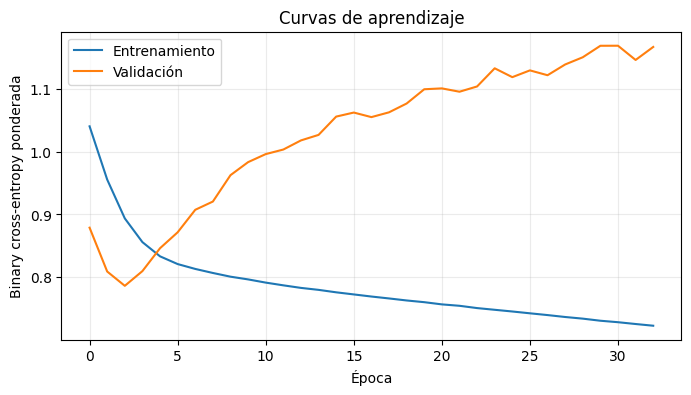

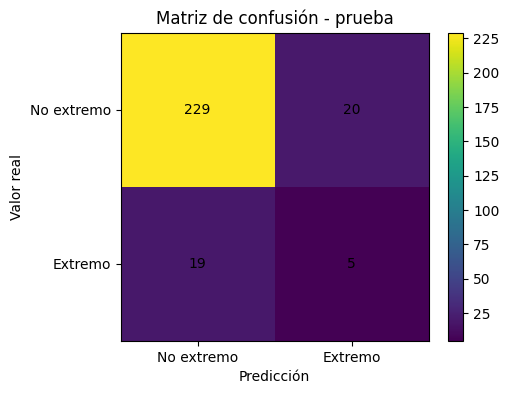

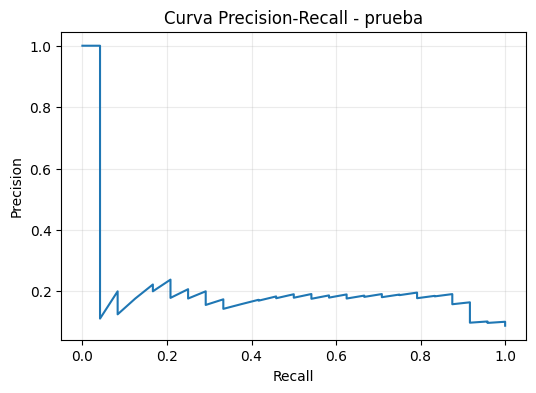

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(hist_train, label="Entrenamiento")
plt.plot(hist_val, label="Validación")
plt.xlabel("Época")
plt.ylabel("Binary cross-entropy ponderada")
plt.title("Curvas de aprendizaje")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Matriz de confusión - prueba")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0,1], ["No extremo", "Extremo"])
plt.yticks([0,1], ["No extremo", "Extremo"])
for (i,j), valor in np.ndenumerate(cm):
    plt.text(j, i, str(valor), ha="center", va="center")
plt.colorbar()
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_test)
plt.figure(figsize=(6, 4))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall - prueba")
plt.grid(alpha=0.25)
plt.show()

## BLOQUE 19. Importancia exploratoria de características por permutación

**Objetivo.** Estimar cuánto empeora el F1 de prueba cuando se desordena una característica, manteniendo las demás intactas.

La importancia se define como:
\[
I_j=F1_{original}-F1_{permutado,j}.
\]

Si el valor es positivo, la permutación perjudicó el resultado y la variable puede aportar información al modelo. Si es cercano a cero o negativo, no se observa contribución predictiva clara en esta evaluación.

**Limitación.** Las variables meteorológicas pueden estar correlacionadas; la importancia por permutación no demuestra causalidad y puede repartir o subestimar la contribución entre variables relacionadas.

,Variable,Disminución de F1
7,amplitud_termica,0.145258
8,mes_sin,0.061224
1,temperatura_maxima,0.033869
9,mes_cos,0.008003
5,lluvia_acumulada_3d,0.008003
6,lluvia_acumulada_7d,0.000000
2,temperatura_minima,0.000000
0,precipitacion_actual,-0.008684
3,humedad_relativa,-0.008684
11,dia_anual_cos,-0.018141


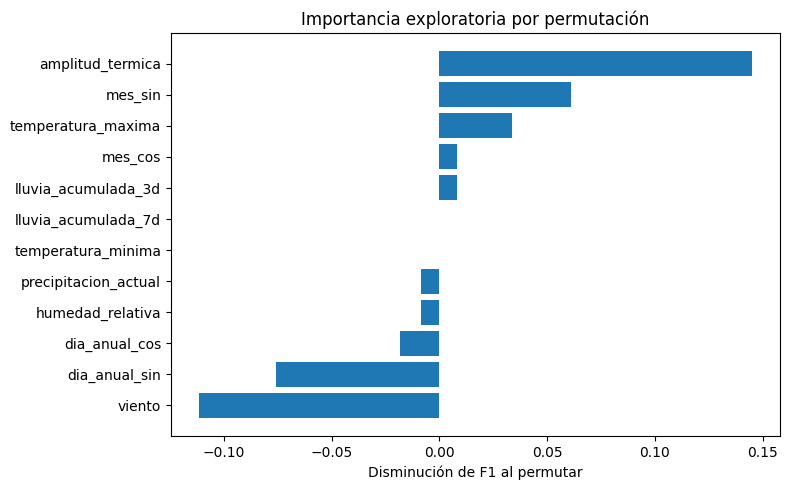

In [ ]:
rng_perm = np.random.default_rng(SEED + 1)
f1_original = f1_score(y_test, y_pred, zero_division=0)
importancias = []

for j, nombre in enumerate(FEATURES):
    X_perm = X_test.copy()
    X_perm[:, j] = rng_perm.permutation(X_perm[:, j])
    p_perm, _ = forward(X_perm, params)
    pred_perm = (p_perm.ravel() >= UMBRAL_DECISION).astype(int)
    f1_perm = f1_score(y_test, pred_perm, zero_division=0)
    importancias.append((nombre, f1_original - f1_perm))

imp_df = pd.DataFrame(importancias, columns=["Variable", "Disminución de F1"]).sort_values("Disminución de F1", ascending=False)
display(imp_df)
plt.figure(figsize=(8,5))
plt.barh(imp_df["Variable"][::-1], imp_df["Disminución de F1"][::-1])
plt.xlabel("Disminución de F1 al permutar")
plt.title("Importancia exploratoria por permutación")
plt.tight_layout()
plt.show()

## BLOQUE 20. Exportación de predicciones y parámetros

Se exportan las predicciones del período de prueba con fecha, precipitación observada, etiqueta real, probabilidad estimada y clase predicha.

También se guarda un archivo `.npz` con pesos, sesgos y parámetros de preprocesamiento. Este archivo permite reconstruir la inferencia sin volver a entrenar, siempre que se utilicen las mismas características y el mismo orden.

In [ ]:
salida = test_df[["fecha", "fecha_objetivo", "precipitacion_objetivo", "target"]].copy()
salida = salida.rename(columns={
    "precipitacion_objetivo": "precipitacion_observada_mm",
    "target": "evento_extremo_real"
})
salida["probabilidad_extremo"] = p_test
salida["evento_extremo_predicho"] = y_pred
salida.to_csv("predicciones_prueba_numpy.csv", index=False)

np.savez(
    "modelo_red_numpy_precipitacion.npz",
    **params,
    medianas=medianas,
    media=media,
    desviacion=desviacion,
    umbral_extremo=UMBRAL_EXTREMO,
    umbral_decision=UMBRAL_DECISION,
    features=np.array(FEATURES),
    pos_weight=POS_WEIGHT
)

print("Archivos generados:")
print("- predicciones_prueba_numpy.csv")
print("- modelo_red_numpy_precipitacion.npz")
display(salida.head(300))

Archivos generados:
- predicciones_prueba_numpy.csv
- modelo_red_numpy_precipitacion.npz


,fecha,fecha_objetivo,precipitacion_observada_mm,evento_extremo_real,probabilidad_extremo,evento_extremo_predicho
1546,2025-12-31,2026-01-01,0.4,0,0.667637,0
1547,2026-01-01,2026-01-02,4.0,0,0.654287,0
1548,2026-01-02,2026-01-03,0.0,0,0.654546,0
1549,2026-01-03,2026-01-04,1.6,0,0.590643,0
1550,2026-01-04,2026-01-05,0.0,0,0.710960,1
...,...,...,...,...,...,...
1814,2026-09-25,2026-09-26,0.0,0,0.120130,0
1815,2026-09-26,2026-09-27,0.0,0,0.092315,0
1816,2026-09-27,2026-09-28,0.0,0,0.092739,0
1817,2026-09-28,2026-09-29,0.0,0,0.164491,0


## BLOQUE 21. Conclusiones, interpretación y limitaciones

### Qué responde el modelo
El modelo estima la probabilidad de que la precipitación del día siguiente alcance el percentil 95 definido en el período de entrenamiento.

### Cómo interpretar el resultado
- Una probabilidad alta representa mayor evidencia estadística de pertenecer a la clase extrema según el umbral adoptado.
- Un falso negativo es un evento extremo no detectado.
- Un falso positivo es una alerta de precipitación extrema que no se confirmó en la observación.
- Recall bajo significa que se escapan muchos eventos; precision baja significa que muchas alertas son falsas.

### Limitaciones que deben declararse
1. Una sola estación meteorológica y una serie de aproximadamente cinco años limitan la generalización espacial y temporal.
2. El percentil 95 es una definición estadística relativa a esta muestra; no es un umbral oficial de peligro.
3. No hay mediciones de caudal, nivel de río, humedad del suelo, topografía detallada ni inventario de inundaciones.
4. El desbalance de clases y el número reducido de eventos extremos hacen que las métricas sean inestables.
5. La red neuronal es una herramienta experimental y no debe utilizarse como sistema operativo de alerta.

### Trabajo futuro
Incorporar varias estaciones, datos de caudal y nivel de ríos, registros históricos de inundación y validación temporal por años. También comparar modelos y evaluar la utilidad de las alertas en función del costo de falsas alarmas y eventos no detectados.

### Conclusión académica
Se implementó una red neuronal MLP desde cero con NumPy, incluyendo inicialización de parámetros, propagación hacia adelante, función de pérdida, backpropagation y optimización Adam. La calidad final debe discutirse a partir de las métricas observadas en el conjunto de prueba, priorizando la detección de eventos extremos y no solamente la exactitud global.